# MobileNetV2 — CMU Face Pose Classification

This notebook uses the same train/validation/test image loading procedure as the Model B notebook, then prepares the grayscale images for MobileNetV2 and performs transfer learning/fine-tuning.

## 1. Check Dataset

In [1]:
from pathlib import Path

dataset_path = Path("D:\\UOM\\Sem 5\\Pattern\\Assignment03\\RocogniX_Classification_Assignment\\split")

for split in ["train", "validation", "test"]:
    folder = dataset_path / split
    files = list(folder.rglob("*.pgm"))

    print(f"{split}: {len(files)} images")
    print("Example files:")
    for f in files[:5]:
        print("  ", f)
    print()

train: 436 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_sad_sunglasses_2.pgm

validation: 93 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_right_angry_sunglasses

In [2]:
from PIL import Image

for split in ["train", "validation", "test"]:
    files = list((dataset_path / split).rglob("*.pgm"))

    print(f"\n{split}")
    for f in files[:5]:
        img = Image.open(f)
        print(f.name, "→", img.size, img.mode)


train
an2i_left_happy_open_2.pgm → (64, 60) L
an2i_left_happy_sunglasses_2.pgm → (64, 60) L
an2i_left_neutral_open_2.pgm → (64, 60) L
an2i_left_neutral_sunglasses_2.pgm → (64, 60) L
an2i_left_sad_sunglasses_2.pgm → (64, 60) L

validation
an2i_left_angry_open_2.pgm → (64, 60) L
an2i_left_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_neutral_sunglasses_2.pgm → (64, 60) L

test
an2i_left_sad_open_2.pgm → (64, 60) L
an2i_up_angry_sunglasses_2.pgm → (64, 60) L
an2i_up_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_sad_open_2.pgm → (64, 60) L
at33_left_angry_open_2.pgm → (64, 60) L


In [3]:
from collections import Counter

poses = ["straight", "left", "right", "up"]

for split in ["train", "validation", "test"]:
    files = list((dataset_path / split).rglob("*.pgm"))
    counts = Counter()

    for f in files:
        parts = f.stem.split("_")
        pose = parts[1]
        counts[pose] += 1

    print(f"\n{split}:")
    for pose in poses:
        print(f"{pose:8s}: {counts[pose]}")


train:
straight: 109
left    : 105
right   : 113
up      : 109

validation:
straight: 26
left    : 25
right   : 23
up      : 19

test:
straight: 21
left    : 27
right   : 19
up      : 28


## 2. Load Dataset into NumPy

In [4]:
from pathlib import Path
from PIL import Image
import numpy as np

# Use the same relative path as the Model B notebook.
# If this notebook is saved in a different folder, change this path.
DATASET_PATH = Path("../split")

CLASS_TO_INDEX = {
    "straight": 0,
    "left": 1,
    "right": 2,
    "up": 3
}

CLASS_NAMES = list(CLASS_TO_INDEX.keys())

def load_dataset(split):
    folder = DATASET_PATH / split

    images = []
    labels = []

    files = sorted(folder.glob("*.pgm"))

    for file in files:
        # Example filename: an2i_left_happy_open_2.pgm
        pose = file.stem.split("_")[1]
        label = CLASS_TO_INDEX[pose]

        # Load grayscale image
        image = np.array(Image.open(file), dtype=np.float32)

        # Same normalization used for Model B: 0-255 -> 0-1
        image /= 255.0

        # Add channel dimension: (60,64) -> (60,64,1)
        image = np.expand_dims(image, axis=-1)

        images.append(image)
        labels.append(label)

    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.int64)

In [5]:
X_train, y_train = load_dataset("train")
X_val, y_val = load_dataset("validation")
X_test, y_test = load_dataset("test")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:  ", X_val.shape)
print("y_val:  ", y_val.shape)
print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)
print("\nPixel range:", X_train.min(), "to", X_train.max())
print("Classes:", CLASS_TO_INDEX)

X_train: (436, 60, 64, 1)
y_train: (436,)
X_val:   (93, 60, 64, 1)
y_val:   (93,)
X_test:  (95, 60, 64, 1)
y_test:  (95,)

Pixel range: 0.0 to 0.9882353
Classes: {'straight': 0, 'left': 1, 'right': 2, 'up': 3}


## 3. Prepare Images for MobileNetV2

The CMU images are grayscale `(60, 64, 1)`. MobileNetV2 expects 3-channel input, so the grayscale channel is repeated three times. The values remain in `0–1`; the model below converts them internally to the `-1–1` range used by MobileNetV2.

In [6]:
# Convert grayscale -> 3 channels
X_train_mobilenet = np.repeat(X_train, 3, axis=-1)
X_val_mobilenet = np.repeat(X_val, 3, axis=-1)
X_test_mobilenet = np.repeat(X_test, 3, axis=-1)

print("X_train_mobilenet:", X_train_mobilenet.shape)
print("X_val_mobilenet:  ", X_val_mobilenet.shape)
print("X_test_mobilenet: ", X_test_mobilenet.shape)
print("Pixel range:", X_train_mobilenet.min(), "to", X_train_mobilenet.max())

X_train_mobilenet: (436, 60, 64, 3)
X_val_mobilenet:   (93, 60, 64, 3)
X_test_mobilenet:  (95, 60, 64, 3)
Pixel range: 0.0 to 0.9882353


## 4. Build MobileNetV2 Transfer-Learning Model

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

base_mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(60, 64, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained feature extractor for the first training stage
base_mobilenet.trainable = False

model_MobileNetV2 = models.Sequential([
    layers.Input(shape=(60, 64, 3)),

    # Convert 0-1 input to -1 to +1 for MobileNetV2
    layers.Rescaling(2.0, offset=-1.0),

    base_mobilenet,

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

model_MobileNetV2.summary()
print("Total parameters:", model_MobileNetV2.count_params())

C:\Users\Sandul\AppData\Local\Temp\ipykernel_27896\740372940.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_mobilenet = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 60, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total parameters: 2422468


## 5. Train Classification Head

In [8]:
from tensorflow.keras.optimizers import Adam

model_MobileNetV2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [9]:
history_MobileNetV2_head = model_MobileNetV2.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(X_val_mobilenet, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 12s 543ms/step - accuracy: 0.4748 - loss: 1.2536 - val_accuracy: 0.6452 - val_loss: 0.8277
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.8326 - loss: 0.5195 - val_accuracy: 0.7849 - val_loss: 0.5632
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.9014 - loss: 0.3175 - val_accuracy: 0.8817 - val_loss: 0.3974
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9564 - loss: 0.2069 - val_accuracy: 0.9032 - val_loss: 0.3165
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.9885 - loss: 0.1235 - val_accuracy: 0.9247 - val_loss: 0.2741
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.9771 - loss: 0.1017 - val_accuracy: 0.9355 - val_loss: 0.2370
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9931 - loss: 0.0701 - val_accuracy: 0.9355 - val_loss: 0.2149
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.9954 - loss: 0.0550 - val_accuracy: 0.9462 -

## 6. Fine-Tune MobileNetV2

After training the new classification head, unfreeze the later MobileNetV2 layers and continue training with a much smaller learning rate.

In [10]:
# Unfreeze the base model
base_mobilenet.trainable = True

# Freeze the earlier layers and fine-tune only the later layers
fine_tune_from = len(base_mobilenet.layers) - 30

for layer in base_mobilenet.layers[:fine_tune_from]:
    layer.trainable = False

# Keep BatchNorm layers frozen because the dataset is small
for layer in base_mobilenet.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers in MobileNetV2:", sum(layer.trainable for layer in base_mobilenet.layers))

Trainable layers in MobileNetV2: 19


In [11]:
model_MobileNetV2.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history_MobileNetV2_finetune = model_MobileNetV2.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(X_val_mobilenet, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 623ms/step - accuracy: 0.9977 - loss: 0.0060 - val_accuracy: 0.9355 - val_loss: 0.1712
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.9977 - loss: 0.0068 - val_accuracy: 0.9247 - val_loss: 0.2521
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 1.0000 - loss: 0.0046 - val_accuracy: 0.9355 - val_loss: 0.2208
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 1.0000 - loss: 0.0030 - val_accuracy: 0.9570 - val_loss: 0.1504
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 0.9570 - val_loss: 0.1492
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 1.0000 - loss: 0.0031 - val_accuracy: 0.9462 - val_loss: 0.1104
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.9570 - val_loss: 0.1249
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 0.9355 -

## 7. Evaluate MobileNetV2

In [13]:
test_loss_MobileNetV2, test_accuracy_MobileNetV2 = model_MobileNetV2.evaluate(
    X_test_mobilenet,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss_MobileNetV2:.4f}")
print(f"Test Accuracy: {test_accuracy_MobileNetV2:.4f}")
print(f"Test Accuracy: {test_accuracy_MobileNetV2*100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9789 - loss: 0.1780
Test Loss: 0.1780
Test Accuracy: 0.9789
Test Accuracy: 97.89%


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 822ms/step


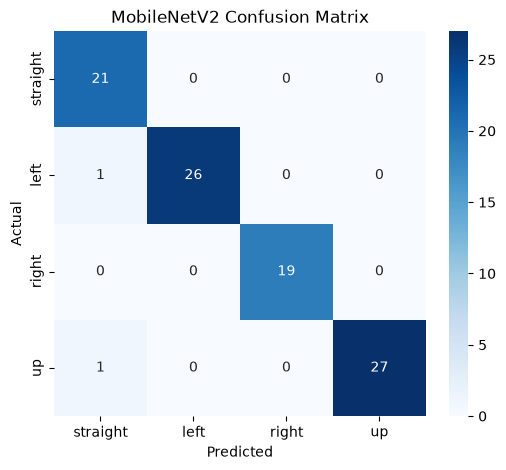

              precision    recall  f1-score   support

    straight     0.9130    1.0000    0.9545        21
        left     1.0000    0.9630    0.9811        27
       right     1.0000    1.0000    1.0000        19
          up     1.0000    0.9643    0.9818        28

    accuracy                         0.9789        95
   macro avg     0.9783    0.9818    0.9794        95
weighted avg     0.9808    0.9789    0.9792        95



In [14]:
y_pred_prob_MobileNetV2 = model_MobileNetV2.predict(X_test_mobilenet)
y_pred_MobileNetV2 = np.argmax(y_pred_prob_MobileNetV2, axis=1)

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_MobileNetV2)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred_MobileNetV2,
    target_names=CLASS_NAMES,
    digits=4
))

## 8. Model Size and Parameter Count

In [15]:
params = model_MobileNetV2.count_params()
print(f"Total parameters: {params:,}")

# Approximate FP32 weight size
size_mb_fp32 = params * 4 / (1024 ** 2)
print(f"Estimated FP32 weight size: {size_mb_fp32:.2f} MB")

# Save model for the final comparison
model_MobileNetV2.save("MobileNetV2_CMU_Face.keras")

Total parameters: 2,422,468
Estimated FP32 weight size: 9.24 MB
